# Emotion Detection — Fine-Tuned Multi-Backbone Fusion Model (Class-Weighted)

Self-contained notebook. Combines VGG16 + ResNet50 + InceptionV3 as parallel branches feeding one classifier, with architecture-aware fine-tuning (only the task-specific blocks unfrozen) and `class_weight` for handling class imbalance directly on real images (SMOTE does not apply here — see the markdown cell below for why).

**⚠️ Heavier than the single-model notebooks** — 3 full backbones loaded and partially fine-tuned at once. Make sure GPU (T4) is selected and internet is ON (for downloading the 3 sets of ImageNet weights).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import random
import shutil
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization, Rescaling,
                                     RandomFlip, RandomRotation, RandomZoom)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
# Apna exact dataset path yahan check karo (left panel se copy karke)
KAGGLE_INPUT_PATH = "/kaggle/input/datasets/msambare/fer2013"   # <-- ye apne dataset ke exact path se match karo

print("Available folders:", os.listdir(KAGGLE_INPUT_PATH))

Available folders: ['test', 'train']


In [3]:
train_dir = os.path.join(KAGGLE_INPUT_PATH, "train")
test_dir = os.path.join(KAGGLE_INPUT_PATH, "test")

ORIGINAL_BASE = "/kaggle/working/original_images"
original_train_dir = os.path.join(ORIGINAL_BASE, "train")
original_val_dir = os.path.join(ORIGINAL_BASE, "validation")

split_ratio = 0.2  # 20% validation

os.makedirs(original_train_dir, exist_ok=True)
os.makedirs(original_val_dir, exist_ok=True)

classes = os.listdir(train_dir)

for cls in classes:
    src_class_path = os.path.join(train_dir, cls)
    val_class_path = os.path.join(original_val_dir, cls)
    train_class_path = os.path.join(original_train_dir, cls)
    os.makedirs(val_class_path, exist_ok=True)
    os.makedirs(train_class_path, exist_ok=True)

    images = os.listdir(src_class_path)
    random.seed(42)
    random.shuffle(images)

    val_count = int(len(images) * split_ratio)
    val_images = images[:val_count]
    train_images = images[val_count:]

    for img in val_images:
        shutil.copy(os.path.join(src_class_path, img), os.path.join(val_class_path, img))
    for img in train_images:
        shutil.copy(os.path.join(src_class_path, img), os.path.join(train_class_path, img))

    print(f"{cls}: train={len(train_images)}, val={len(val_images)}")

print("\n✅ original_images (raw, untouched) ready at", ORIGINAL_BASE)

surprise: train=2537, val=634
fear: train=3278, val=819
angry: train=3196, val=799
neutral: train=3972, val=993
sad: train=3864, val=966
disgust: train=349, val=87
happy: train=5772, val=1443

✅ original_images (raw, untouched) ready at /kaggle/working/original_images


In [4]:
for cls in os.listdir(original_train_dir):
    t_count = len(os.listdir(os.path.join(original_train_dir, cls)))
    v_count = len(os.listdir(os.path.join(original_val_dir, cls)))
    print(f"{cls}: train={t_count}, val={v_count}")

angry: train=3196, val=799
fear: train=3278, val=819
neutral: train=3972, val=993
sad: train=3864, val=966
happy: train=5772, val=1443
surprise: train=2537, val=634
disgust: train=349, val=87


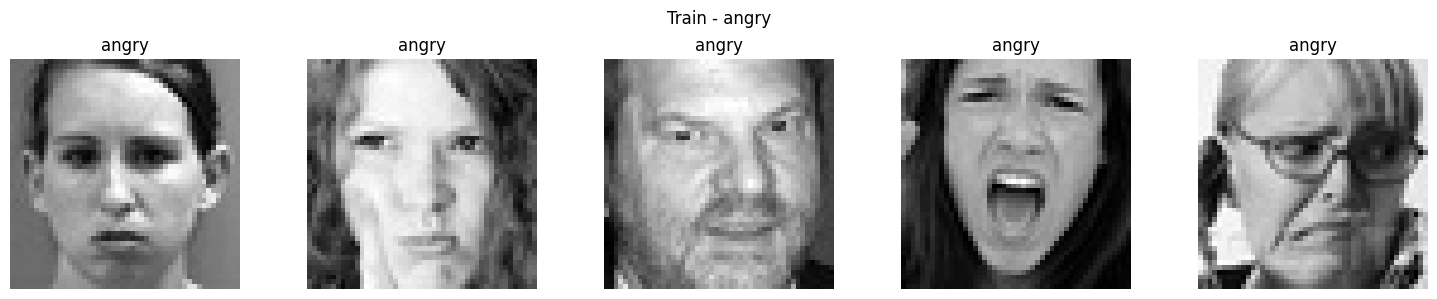

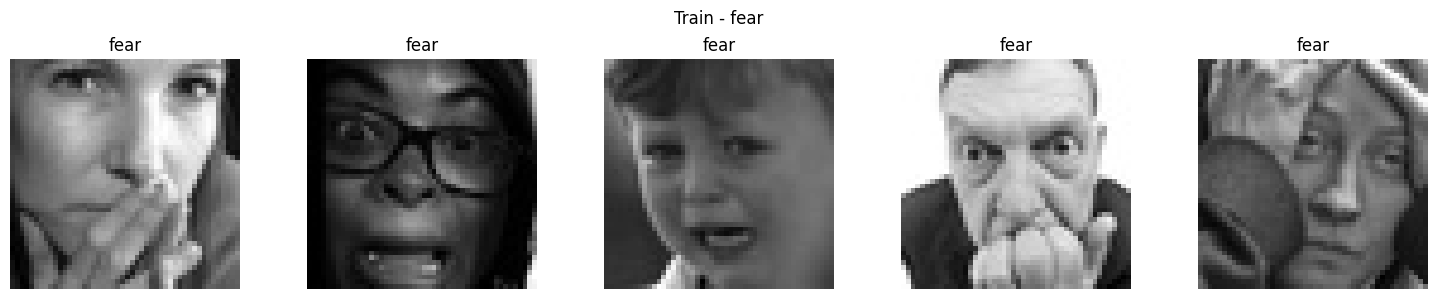

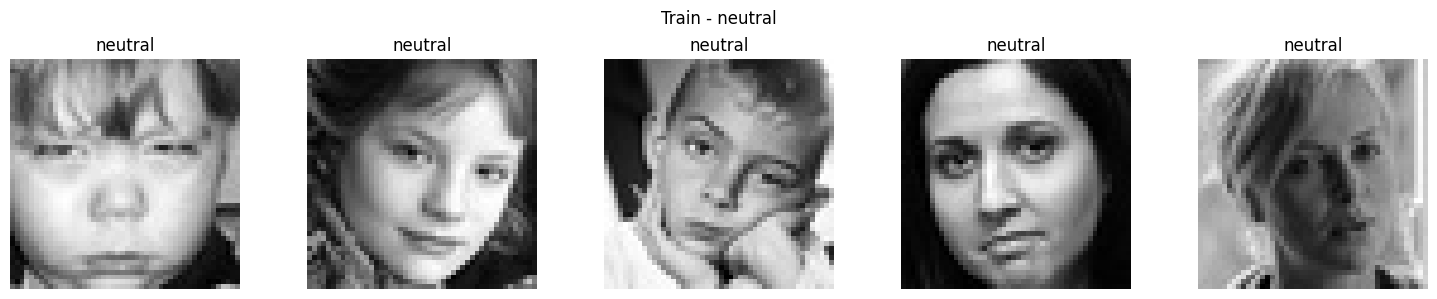

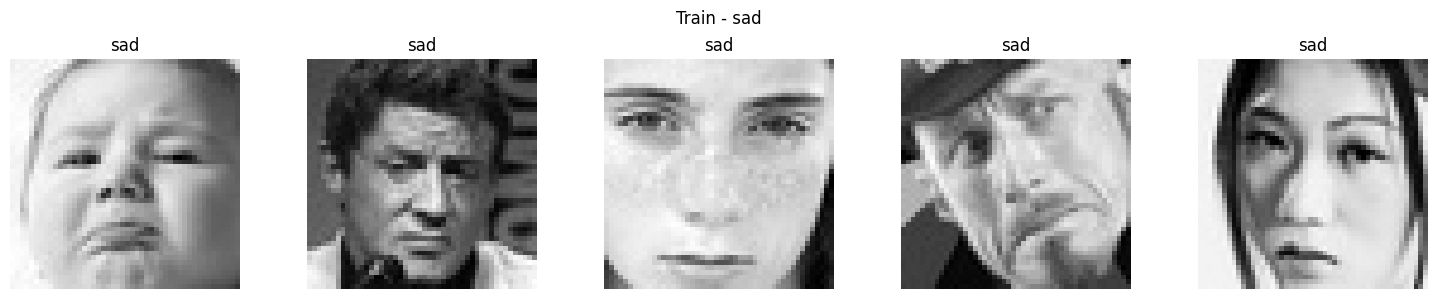

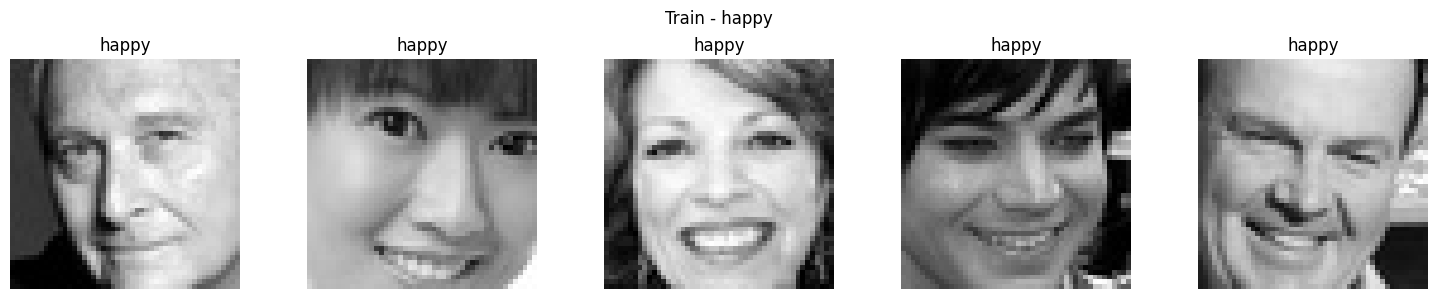

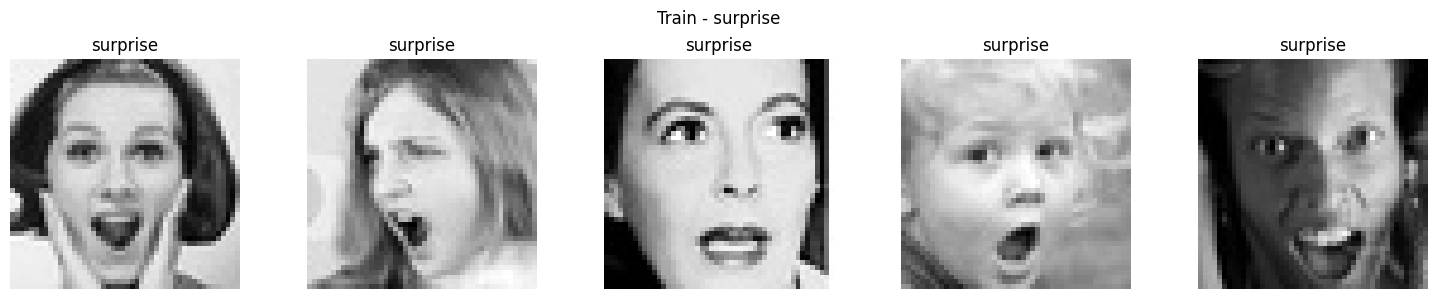

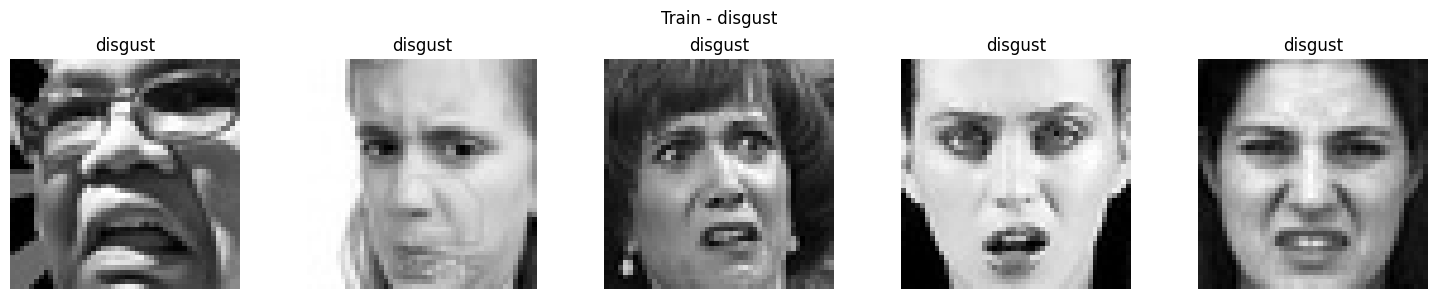

In [5]:
def show_sample_images(path, title):
    classes = os.listdir(path)
    for class_name in classes:
        class_dir = os.path.join(path, class_name)
        images_files = os.listdir(class_dir)
        random_images = random.sample(images_files, min(5, len(images_files)))

        plt.figure(figsize=(15, 3))
        for index, img_name in enumerate(random_images):
            img = Image.open(os.path.join(class_dir, img_name))
            plt.subplot(1, 5, index + 1)
            plt.imshow(img, cmap="gray")
            plt.title(class_name)
            plt.axis("off")
        plt.suptitle(f"{title} - {class_name}")
        plt.tight_layout()
        plt.show()

show_sample_images(original_train_dir, "Train")

In [6]:
PREPROCESSED_BASE = "/kaggle/working/preprocessed_images"

if os.path.exists(PREPROCESSED_BASE):
    shutil.rmtree(PREPROCESSED_BASE)

shutil.copytree(ORIGINAL_BASE, PREPROCESSED_BASE)

preprocessed_train_dir = os.path.join(PREPROCESSED_BASE, "train")
preprocessed_val_dir = os.path.join(PREPROCESSED_BASE, "validation")

print("✅ preprocessed_images folder ready (copy of original_images)")
print("Location:", PREPROCESSED_BASE)

✅ preprocessed_images folder ready (copy of original_images)
Location: /kaggle/working/preprocessed_images


In [7]:
def md5_hasher(file_path):
    hasher = hashlib.md5()
    with open(file_path, "rb") as f:
        hasher.update(f.read())
    return hasher.hexdigest()

def find_duplicates(folder_path):
    hashes = {}
    duplicates = []
    error_count = 0

    for root, dirs, files in os.walk(folder_path):
        for file in files:
            file_path = os.path.join(root, file)
            try:
                file_hash = md5_hasher(file_path)
                if file_hash in hashes:
                    duplicates.append((file_path, hashes[file_hash]))
                else:
                    hashes[file_hash] = file_path
            except Exception:
                error_count += 1

    return duplicates, error_count

dups, errors = find_duplicates(PREPROCESSED_BASE)
print(f"Total duplicate files found: {len(dups)}")
print(f"Total unreadable files (skipped): {errors}")

Total duplicate files found: 1236
Total unreadable files (skipped): 0


In [8]:
deleted_count = 0
error_count = 0
not_found_count = 0

for dup in dups:
    duplicate_file = dup[0]
    if os.path.exists(duplicate_file):
        try:
            os.remove(duplicate_file)
            deleted_count += 1
        except Exception:
            error_count += 1
    else:
        not_found_count += 1

print(f"✅ Deleted: {deleted_count}")
print(f"⚠️ Errors: {error_count}")
print(f"⚠️ Already missing: {not_found_count}")

✅ Deleted: 1236
⚠️ Errors: 0
⚠️ Already missing: 0


In [9]:
dups_check, _ = find_duplicates(PREPROCESSED_BASE)
print(f"Remaining duplicates in preprocessed_images: {len(dups_check)}")

Remaining duplicates in preprocessed_images: 0


In [10]:
data = []

def count_images(main_dir, phase):
    for cls in os.listdir(os.path.join(main_dir, "train")):
        count = len(os.listdir(os.path.join(main_dir, "train", cls)))
        data.append({"Class": cls, "Images Count": count, "Phase": phase})

count_images(ORIGINAL_BASE, "Before (original_images)")
count_images(PREPROCESSED_BASE, "After (preprocessed_images)")

df = pd.DataFrame(data)
comparison_df = df.pivot_table(index="Class", columns="Phase", values="Images Count", fill_value=0).reset_index()
comparison_df

Phase,Class,After (preprocessed_images),Before (original_images)
0,angry,3086.0,3196.0
1,disgust,316.0,349.0
2,fear,3159.0,3278.0
3,happy,5689.0,5772.0
4,neutral,3913.0,3972.0
5,sad,3783.0,3864.0
6,surprise,2201.0,2537.0


In [11]:
def check_corrupt_images(directory):
    corrupt_images = []
    for root, dirs, files in os.walk(directory):
        for file in files:
            path = os.path.join(root, file)
            try:
                img = Image.open(path)
                img.verify()
            except Exception:
                corrupt_images.append(path)
    return corrupt_images

corrupt_train = check_corrupt_images(preprocessed_train_dir)
corrupt_val = check_corrupt_images(preprocessed_val_dir)
print(f"Corrupt images in train: {len(corrupt_train)}")

Corrupt images in train: 0


In [12]:
# checking the unique file formats i have in these folders
def check_unique_file_formats(folder_path):
    extensions = []
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            file_extension = os.path.splitext(file)[1]
            if file_extension not in extensions:
                extensions.append(file_extension)
        print(f"Unique files in {root}: {extensions}")
        print("-"*80)

folder_path = "/kaggle/working/original_images"
check_unique_file_formats(folder_path)

Unique files in /kaggle/working/original_images: []
--------------------------------------------------------------------------------
Unique files in /kaggle/working/original_images/train: []
--------------------------------------------------------------------------------
Unique files in /kaggle/working/original_images/train/angry: ['.jpg']
--------------------------------------------------------------------------------
Unique files in /kaggle/working/original_images/train/fear: ['.jpg']
--------------------------------------------------------------------------------
Unique files in /kaggle/working/original_images/train/neutral: ['.jpg']
--------------------------------------------------------------------------------
Unique files in /kaggle/working/original_images/train/sad: ['.jpg']
--------------------------------------------------------------------------------
Unique files in /kaggle/working/original_images/train/happy: ['.jpg']
-------------------------------------------------------

In [13]:
def check_image_size(folder_path) :
    size = []
    for root, dirs, files in os.walk(folder_path) :
        for file in files :
            image_path = os.path.join(root, file)
            with Image.open(image_path) as img:
                image_size = img.size
            if image_size not in size:
                size.append(image_size)

        print(f"Unique image size in {root} : {size}")

folder_path = "/kaggle/working/original_images"
check_image_size(folder_path)

Unique image size in /kaggle/working/original_images : []
Unique image size in /kaggle/working/original_images/train : []
Unique image size in /kaggle/working/original_images/train/angry : [(48, 48)]
Unique image size in /kaggle/working/original_images/train/fear : [(48, 48)]
Unique image size in /kaggle/working/original_images/train/neutral : [(48, 48)]
Unique image size in /kaggle/working/original_images/train/sad : [(48, 48)]
Unique image size in /kaggle/working/original_images/train/happy : [(48, 48)]
Unique image size in /kaggle/working/original_images/train/surprise : [(48, 48)]
Unique image size in /kaggle/working/original_images/train/disgust : [(48, 48)]
Unique image size in /kaggle/working/original_images/validation : [(48, 48)]
Unique image size in /kaggle/working/original_images/validation/angry : [(48, 48)]
Unique image size in /kaggle/working/original_images/validation/fear : [(48, 48)]
Unique image size in /kaggle/working/original_images/validation/neutral : [(48, 48)]
U

In [14]:
# Set your directory path
base_path = "/kaggle/working/original_images"

file_data = []

for root, dirs, files in os.walk(base_path):
    for file in files:
        file_path = os.path.join(root, file)
        try:
            size_kb = os.path.getsize(file_path) / 1024
            file_data.append({
                "file_name": file,
                "folder": os.path.relpath(root, base_path),
                "size_kb": round(size_kb, 2)
            })
        except Exception as e:
            print(f"Error reading {file_path}: {e}")

# Create DataFrame
df = pd.DataFrame(file_data)

# Sort by size to detect anomalies
df_sorted = df.sort_values(by="size_kb", ascending=False)
df_sorted

,file_name,folder,size_kb
5954,Training_87394233.jpg,train/fear,2.34
686,Training_98835403.jpg,train/angry,2.31
27257,Training_9066250.jpg,validation/happy,2.28
435,Training_58690193.jpg,train/angry,2.26
20138,Training_82417057.jpg,train/surprise,2.25
...,...,...,...
2178,Training_52563817.jpg,train/angry,0.35
1952,Training_99531165.jpg,train/angry,0.35
19745,Training_87607167.jpg,train/happy,0.35
1502,Training_28756096.jpg,train/angry,0.35


In [15]:
print("Unique File Sizes (KB):")
print(df["size_kb"].unique())
print("Total Files Scanned:", len(df))

Unique File Sizes (KB):
[1.24 1.81 1.52 1.44 1.66 1.64 1.4  1.71 1.55 1.35 1.69 1.75 1.73 1.61
 1.51 1.63 1.48 1.56 1.65 1.36 1.79 1.38 1.58 1.49 1.43 1.68 1.47 1.57
 1.46 1.8  1.5  1.82 1.29 1.67 1.45 1.87 1.62 1.6  1.59 1.32 1.85 1.54
 1.28 1.27 1.3  2.06 1.86 1.72 1.39 1.78 1.76 1.17 1.97 1.33 1.34 1.74
 1.25 1.88 1.7  2.03 1.37 1.31 1.22 1.21 2.23 2.05 1.42 1.23 1.19 1.91
 1.41 1.53 0.35 0.54 1.77 1.26 1.11 1.83 2.26 1.96 2.11 1.89 1.84 0.92
 2.31 1.1  2.13 1.2  1.99 1.12 1.15 1.16 1.13 1.05 1.92 1.08 1.03 2.08
 1.95 1.98 1.04 1.07 1.14 2.24 1.09 1.9  2.17 0.93 2.04 1.18 1.93 2.09
 0.98 2.   0.95 1.94 2.07 2.16 0.94 2.02 2.15 2.21 2.12 0.84 0.55 1.02
 1.   1.01 2.18 0.97 2.34 0.96 1.06 0.66 2.01 0.45 0.82 2.2  0.99 0.71
 2.1  0.77 0.87 2.25 0.91 0.68 2.19 2.14 2.28 0.81 0.85]
Total Files Scanned: 28709


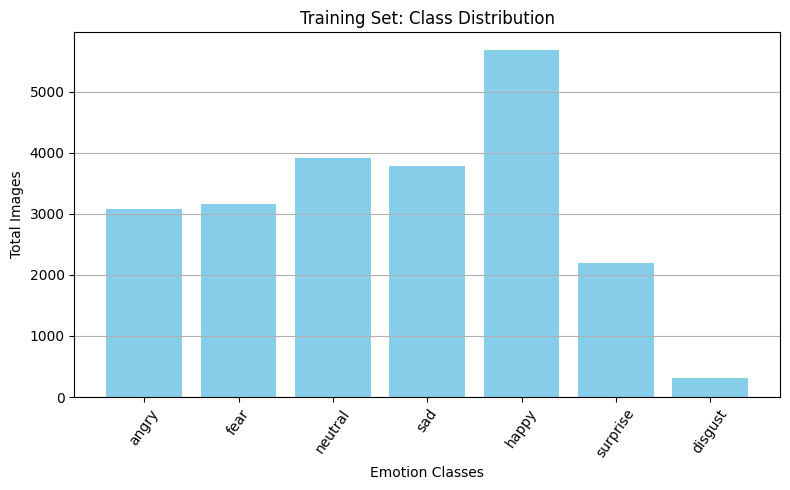

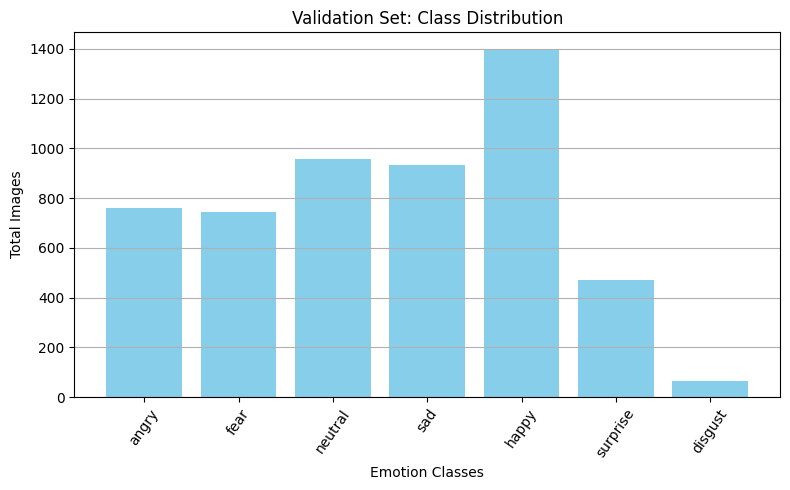

In [16]:
def plot_class_distribution(directory, title):
    classes = os.listdir(directory)
    counts = [len(os.listdir(os.path.join(directory, cls))) for cls in classes]

    plt.figure(figsize=(8, 5))
    plt.bar(classes, counts, color="skyblue")
    plt.xlabel("Emotion Classes")
    plt.ylabel("Total Images")
    plt.title(title)
    plt.xticks(rotation=55)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()

plot_class_distribution(preprocessed_train_dir, "Training Set: Class Distribution")
plot_class_distribution(preprocessed_val_dir, "Validation Set: Class Distribution")

In [17]:
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers, models

train_dir = "/kaggle/working/preprocessed_images/train"
val_dir = "/kaggle/working/preprocessed_images/validation"
IMG_SIZE = (224, 224)
NUM_CLASSES = 7
BATCH_SIZE = 32

# Grayscale images load karo (raw 48x48), preprocessing baad me model-specific hogi
raw_train_ds = image_dataset_from_directory(
    train_dir, labels="inferred", label_mode="categorical",
    color_mode="grayscale", image_size=(48, 48), batch_size=BATCH_SIZE, shuffle=True
)
raw_val_ds = image_dataset_from_directory(
    val_dir, labels="inferred", label_mode="categorical",
    color_mode="grayscale", image_size=(48, 48), batch_size=BATCH_SIZE, shuffle=False
)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

def make_preprocess_fn(preprocess_input_fn, img_size=IMG_SIZE):
    # Grayscale(48x48) -> RGB -> resize -> augment -> model-specific preprocess_input
    def _fn(image, label):
        image = tf.image.grayscale_to_rgb(image)
        image = tf.image.resize(image, img_size, method="bicubic")
        image = data_augmentation(image)
        image = preprocess_input_fn(image)
        return image, label
    return _fn

def build_transfer_model(base_model_class, img_size=IMG_SIZE, num_classes=NUM_CLASSES):
    base_model = base_model_class(input_shape=(*img_size, 3), include_top=False, weights="imagenet")
    base_model.trainable = False  # Phase 1: freeze base

    inputs = layers.Input(shape=(*img_size, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)

    model = models.Model(inputs, outputs)
    return model, base_model

def get_callbacks(checkpoint_name, es_patience=8, lr_patience=3):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=checkpoint_name, monitor="val_accuracy",
            save_best_only=True, mode="max", verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=es_patience, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=lr_patience, verbose=1
        )
    ]

class_names = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]

print("Common data pipeline aur helper functions ready ✅")
print("Ab neeche VGG16 / ResNet50 / InceptionV3 wale cells directly run karo.")

Found 22147 files belonging to 7 classes.


I0000 00:00:1788609815.576753      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788609815.579744      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 5326 files belonging to 7 classes.
Common data pipeline aur helper functions ready ✅
Ab neeche VGG16 / ResNet50 / InceptionV3 wale cells directly run karo.


## Architecture-Aware Fine-Tuning (Layer-Study Based, Not Arbitrary Last-N)

**Why not just unfreeze "the last N layers"?**
Unfreezing an arbitrary number of layers ignores what those layers actually do. CNN feature hierarchies are well-studied (Zeiler & Fergus, 2014; Yosinski et al., 2014):

- **Early layers** (first conv blocks/stages) learn **generic, low-level features** — edges, color blobs, simple textures. These transfer well across almost any image domain, including grayscale faces, so they should be **frozen and used as-is**.
- **Middle layers** learn **mid-level patterns** — combinations of edges into shapes, simple parts. Somewhat generic, somewhat task-specific.
- **Late layers** learn **high-level, task-specific semantics** — object parts and class-discriminative features tuned to the original 1000 ImageNet classes. Since our task (facial emotion recognition on grayscale 48×48 faces) is very different from ImageNet, these layers need to be **retrained (unfrozen)** so they can re-specialize toward emotion-relevant facial features.

Below, each architecture's actual named blocks/stages are inspected first, then trainability is set **by named block**, not by counting layers from the end.

In [18]:
# ================= Inspect block/stage structure of each architecture =================
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3

def summarize_blocks(base_model, group_fn):
    groups = {}
    for layer in base_model.layers:
        g = group_fn(layer.name)
        groups.setdefault(g, []).append(layer.name)
    for g, names in groups.items():
        print(f"{g:15s} -> {len(names):3d} layers   (e.g. {names[0]})")

print("=== VGG16 blocks ===")
vgg_temp = VGG16(include_top=False, weights=None, input_shape=(224, 224, 3))
summarize_blocks(vgg_temp, lambda n: n.split("_")[0] if "_" in n else n)

print("\n=== ResNet50 stages ===")
resnet_temp = ResNet50(include_top=False, weights=None, input_shape=(224, 224, 3))
summarize_blocks(resnet_temp, lambda n: n.split("_")[0])

print("\n=== InceptionV3 mixed blocks ===")
inception_temp = InceptionV3(include_top=False, weights=None, input_shape=(224, 224, 3))
summarize_blocks(inception_temp, lambda n: n.split("_")[0] if n.startswith("mixed") else "stem_conv")

del vgg_temp, resnet_temp, inception_temp

=== VGG16 blocks ===
input           ->   1 layers   (e.g. input_layer)
block1          ->   3 layers   (e.g. block1_conv1)
block2          ->   3 layers   (e.g. block2_conv1)
block3          ->   4 layers   (e.g. block3_conv1)
block4          ->   4 layers   (e.g. block4_conv1)
block5          ->   4 layers   (e.g. block5_conv1)

=== ResNet50 stages ===
input           ->   1 layers   (e.g. input_layer_1)
conv1           ->   4 layers   (e.g. conv1_pad)
pool1           ->   2 layers   (e.g. pool1_pad)
conv2           ->  32 layers   (e.g. conv2_block1_1_conv)
conv3           ->  42 layers   (e.g. conv3_block1_1_conv)
conv4           ->  62 layers   (e.g. conv4_block1_1_conv)
conv5           ->  32 layers   (e.g. conv5_block1_1_conv)

=== InceptionV3 mixed blocks ===
stem_conv       -> 298 layers   (e.g. input_layer_2)
mixed0          ->   1 layers   (e.g. mixed0)
mixed1          ->   1 layers   (e.g. mixed1)
mixed2          ->   1 layers   (e.g. mixed2)
mixed3          ->   1 layers  

In [19]:
# ================= Block-aware trainable configuration (based on the study above) =================

def configure_vgg16_trainable(base_model, frozen_blocks=("block1", "block2")):
    """block1-block2: generic edge/color features -> frozen (used as-is).
    block3-block5: higher-level, task-specific features -> unfrozen (retrained)."""
    for layer in base_model.layers:
        layer.trainable = not any(layer.name.startswith(b) for b in frozen_blocks)

def configure_resnet50_trainable(base_model, frozen_prefixes=("conv1", "conv2_block")):
    """Stem + stage conv2 (early residual stage): generic features -> frozen.
    conv3-conv5 stages: increasingly task-specific -> unfrozen (retrained)."""
    for layer in base_model.layers:
        layer.trainable = not any(layer.name.startswith(p) for p in frozen_prefixes)

def configure_inceptionv3_trainable(base_model, unfreeze_from="mixed8"):
    """Everything before 'mixed8' (stem convs + Inception blocks mixed0-mixed7):
    generic/mid-level features -> frozen.
    mixed8 onward (final Inception blocks): task-specific -> unfrozen (retrained).
    This matches the widely-used recipe of retraining only the top 2 Inception blocks."""
    unfreeze = False
    for layer in base_model.layers:
        if layer.name.startswith(unfreeze_from):
            unfreeze = True
        layer.trainable = unfreeze

def print_trainable_summary(base_model, name):
    trainable = sum(1 for l in base_model.layers if l.trainable)
    total = len(base_model.layers)
    print(f"{name}: {trainable}/{total} layers trainable ({trainable/total*100:.1f}%)")

## Improvement 1: Class-Weighted Training (fixes class imbalance)

FER2013 is heavily imbalanced (Disgust ~550 images vs Happy ~9000). `class_weight` tells the loss function to penalize mistakes on minority classes more heavily, without needing any extra data or architecture changes.

In [20]:
# ================= Compute class weights from the training set =================
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

def compute_dataset_class_weights(raw_ds, num_classes=7):
    all_labels = []
    for _, labels in raw_ds.unbatch():
        all_labels.append(int(tf.argmax(labels).numpy()))
    all_labels = np.array(all_labels)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(num_classes),
        y=all_labels
    )
    class_weights_dict = dict(enumerate(weights))
    return class_weights_dict

class_weights_dict = compute_dataset_class_weights(raw_train_ds)
print("Class weights:")
for i, cname in enumerate(class_names):
    print(f"  {cname:10s}: {class_weights_dict[i]:.3f}")

Class weights:
  Angry     : 1.025
  Disgust   : 10.012
  Fear      : 1.002
  Happy     : 0.556
  Sad       : 0.809
  Surprise  : 0.836
  Neutral   : 1.437


## Improvement 4: End-to-End Fine-Tuned Multi-Backbone Fusion Model (Class-Weighted)

**Why not SMOTE here:** SMOTE was applied earlier in feature space (on fixed GAP vectors from frozen backbones). Those synthetic feature vectors have no corresponding real image, so they cannot be used to fine-tune the convolutional layers themselves (fine-tuning needs a real image to backpropagate through the conv filters). That is why the earlier SMOTE-fusion classifier could only train a small Dense head on frozen features, and underperformed the individually fine-tuned models.

**This version fixes that** by building one combined model with all three backbones as parallel branches, feeding real images end-to-end:
- Each backbone keeps its "good feature extractor" layers **frozen** (the early blocks/stages identified in the architecture study), and unfreezes only the later, task-specific blocks — same rationale as before, applied to all three at once.
- Class imbalance is handled with **`class_weight`** during training (the correct tool once we're back to training on real images, since SMOTE no longer applies here).
- The three backbones' features are concatenated before the final classifier head, combining what each architecture extracts best.

In [21]:
# ================= Multi-backbone data pipeline (same augmented image, 3 preprocessing branches) =================
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

def make_multi_preprocess_fn(augment=True):
    def _fn(image, label):
        rgb = tf.image.grayscale_to_rgb(image)
        resized = tf.image.resize(rgb, IMG_SIZE, method="bicubic")
        if augment:
            resized = data_augmentation(resized)
        img_vgg = vgg16_preprocess(resized)
        img_resnet = resnet_preprocess(resized)
        img_inception = inception_preprocess(resized)
        return (img_vgg, img_resnet, img_inception), label
    return _fn

multi_train_data = raw_train_ds.map(make_multi_preprocess_fn(augment=True), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
multi_val_data = raw_val_ds.map(make_multi_preprocess_fn(augment=False), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

print("Multi-backbone data pipeline ready")

Multi-backbone data pipeline ready


In [22]:
# ================= Build the combined multi-backbone model =================
def build_multi_backbone_model(img_size=IMG_SIZE, num_classes=NUM_CLASSES):
    input_vgg = layers.Input(shape=(*img_size, 3), name="input_vgg16")
    input_resnet = layers.Input(shape=(*img_size, 3), name="input_resnet50")
    input_inception = layers.Input(shape=(*img_size, 3), name="input_inceptionv3")

    vgg_base = VGG16(input_shape=(*img_size, 3), include_top=False, weights="imagenet", name="vgg16_backbone")
    resnet_base = ResNet50(input_shape=(*img_size, 3), include_top=False, weights="imagenet", name="resnet50_backbone")
    inception_base = InceptionV3(input_shape=(*img_size, 3), include_top=False, weights="imagenet", name="inceptionv3_backbone")

    # start fully frozen -- Phase 1 trains only the fusion head
    vgg_base.trainable = False
    resnet_base.trainable = False
    inception_base.trainable = False

    vgg_feat = layers.GlobalAveragePooling2D(name="vgg_gap")(vgg_base(input_vgg, training=False))
    resnet_feat = layers.GlobalAveragePooling2D(name="resnet_gap")(resnet_base(input_resnet, training=False))
    inception_feat = layers.GlobalAveragePooling2D(name="inception_gap")(inception_base(input_inception, training=False))

    fused = layers.Concatenate(name="fusion_concat")([vgg_feat, resnet_feat, inception_feat])
    x = layers.Dense(512, activation="relu")(fused)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)

    model = models.Model(inputs=[input_vgg, input_resnet, input_inception], outputs=outputs)
    return model, vgg_base, resnet_base, inception_base

multi_model, vgg_base, resnet_base, inception_base = build_multi_backbone_model()
multi_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_vgg16         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_resnet50      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_inceptionv3   │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16_backbone      │ (None, 7, 7, 512) │ 14,714,688 │ input_vgg16[0][0] │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50_backbone   │ (None, 7, 7,      │ 23,587,712 │ input_resnet50[0… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inceptionv3_backbo… │ (None, 5, 5,      │ 21,802,784 │ input_inceptionv… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg_gap             │ (None, 512)       │          0 │ vgg16_backbone[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet_gap          │ (None, 2048)      │          0 │ resnet50_backbon… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_gap       │ (None, 2048)      │          0 │ inceptionv3_back… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_concat       │ (None, 4608)      │          0 │ vgg_gap[0][0],    │
│ (Concatenate)       │                   │            │ resnet_gap[0][0], │
│                     │                   │            │ inception_gap[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │  2,359,808 │ fusion_concat[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    131,328 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 7)         │      1,799 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 62,601,191 (238.80 MB)

 Trainable params: 2,494,471 (9.52 MB)

 Non-trainable params: 60,106,720 (229.29 MB)

In [23]:
# ================= Phase 1: train the fusion head only (all 3 backbones frozen) =================
multi_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

multi_callbacks = get_callbacks("multi_backbone_fusion_phase1.keras")

# class weights computed earlier in "Improvement 1" (compute_dataset_class_weights) -- recompute if not in memory
if "class_weights_dict" not in dir():
    class_weights_dict = compute_dataset_class_weights(raw_train_ds)

history_multi_phase1 = multi_model.fit(
    multi_train_data, validation_data=multi_val_data,
    epochs=25, callbacks=multi_callbacks,
    class_weight=class_weights_dict
)

Epoch 1/25


I0000 00:00:1788609891.397234      74 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


693/693 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.2849 - loss: 2.2380
Epoch 1: val_accuracy improved from None to 0.42377, saving model to multi_backbone_fusion_phase1.keras

Epoch 1: finished saving model to multi_backbone_fusion_phase1.keras
693/693 ━━━━━━━━━━━━━━━━━━━━ 349s 442ms/step - accuracy: 0.3237 - loss: 1.9929 - val_accuracy: 0.4238 - val_loss: 1.5019 - learning_rate: 0.0010
Epoch 2/25
693/693 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.3838 - loss: 1.6578
Epoch 2: val_accuracy improved from 0.42377 to 0.49606, saving model to multi_backbone_fusion_phase1.keras

Epoch 2: finished saving model to multi_backbone_fusion_phase1.keras
693/693 ━━━━━━━━━━━━━━━━━━━━ 316s 387ms/step - accuracy: 0.3926 - loss: 1.6078 - val_accuracy: 0.4961 - val_loss: 1.3188 - learning_rate: 0.0010
Epoch 3/25
693/693 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.4294 - loss: 1.5143
Epoch 3: val_accuracy did not improve from 0.49606
693/693 ━━━━━━━━━━━━━━━━━━━━ 267s 384ms/step - accuracy

In [24]:
# ================= Phase 2: architecture-aware fine-tuning, all 3 backbones, class-weighted =================
# Reuses configure_vgg16_trainable / configure_resnet50_trainable / configure_inceptionv3_trainable
# from the "Architecture-Aware Fine-Tuning" section above -- run that section's cells first if not already run.

configure_vgg16_trainable(vgg_base)
configure_resnet50_trainable(resnet_base)
configure_inceptionv3_trainable(inception_base)

print_trainable_summary(vgg_base, "VGG16")
print_trainable_summary(resnet_base, "ResNet50")
print_trainable_summary(inception_base, "InceptionV3")

multi_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])

history_multi_phase2 = multi_model.fit(
    multi_train_data, validation_data=multi_val_data,
    epochs=22, callbacks=multi_callbacks,
    class_weight=class_weights_dict
)

multi_model.save("final_multi_backbone_fusion_finetuned.keras")
print("Multi-backbone fine-tuned fusion model saved")

VGG16: 13/19 layers trainable (68.4%)
ResNet50: 139/175 layers trainable (79.4%)
InceptionV3: 63/311 layers trainable (20.3%)
Epoch 1/22
693/693 ━━━━━━━━━━━━━━━━━━━━ 0s 690ms/step - accuracy: 0.4608 - loss: 1.4267
Epoch 1: val_accuracy did not improve from 0.56628
693/693 ━━━━━━━━━━━━━━━━━━━━ 640s 789ms/step - accuracy: 0.4761 - loss: 1.3734 - val_accuracy: 0.5306 - val_loss: 1.2848 - learning_rate: 1.0000e-05
Epoch 2/22
693/693 ━━━━━━━━━━━━━━━━━━━━ 0s 641ms/step - accuracy: 0.5221 - loss: 1.2388
Epoch 2: val_accuracy did not improve from 0.56628
693/693 ━━━━━━━━━━━━━━━━━━━━ 497s 715ms/step - accuracy: 0.5243 - loss: 1.2170 - val_accuracy: 0.5447 - val_loss: 1.2021 - learning_rate: 1.0000e-05
Epoch 3/22
693/693 ━━━━━━━━━━━━━━━━━━━━ 0s 640ms/step - accuracy: 0.5512 - loss: 1.1479
Epoch 3: val_accuracy improved from 0.56628 to 0.57867, saving model to multi_backbone_fusion_phase1.keras

Epoch 3: finished saving model to multi_backbone_fusion_phase1.keras
693/693 ━━━━━━━━━━━━━━━━━━━━ 500s

Multi-Backbone Fine-Tuned Fusion Accuracy: 0.6472

              precision    recall  f1-score   support

       Angry     0.6146    0.5315    0.5700       762
     Disgust     0.3750    0.5714    0.4528        63
        Fear     0.5575    0.3901    0.4590       746
       Happy     0.8579    0.8511    0.8545      1397
         Sad     0.5433    0.7155    0.6176       956
    Surprise     0.5595    0.5241    0.5412       933
     Neutral     0.6660    0.7527    0.7067       469

    accuracy                         0.6472      5326
   macro avg     0.5962    0.6195    0.6003      5326
weighted avg     0.6496    0.6472    0.6432      5326



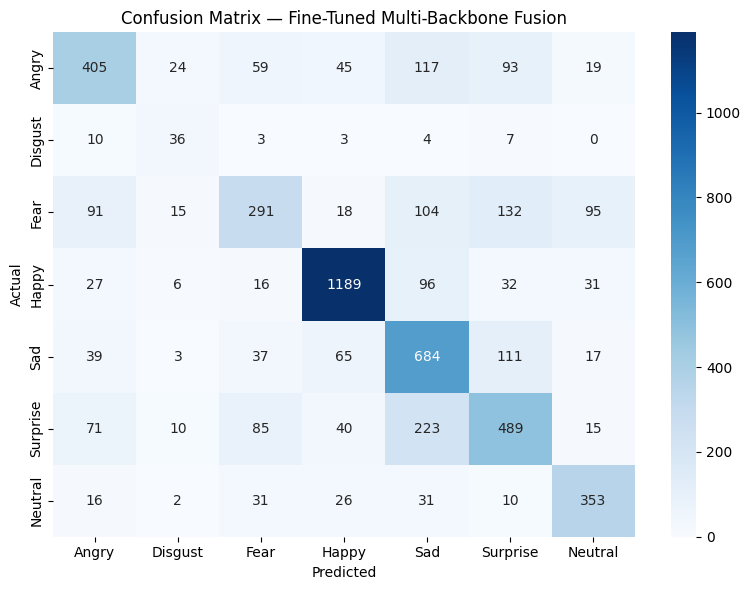

In [25]:
# ================= Evaluate the fine-tuned fusion model =================
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_multi_input_model(model, val_data, class_names):
    y_true, y_pred = [], []
    for images_tuple, labels in val_data:
        preds = model.predict(images_tuple, verbose=0)
        y_true.extend(tf.argmax(labels, axis=1).numpy())
        y_pred.extend(np.argmax(preds, axis=1))
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    acc = (y_true == y_pred).mean()
    print(f"Multi-Backbone Fine-Tuned Fusion Accuracy: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.title("Confusion Matrix — Fine-Tuned Multi-Backbone Fusion")
    plt.tight_layout()
    plt.show()
    return y_true, y_pred

class_names = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
y_true, y_pred = evaluate_multi_input_model(multi_model, multi_val_data, class_names)